# HCC internal val — pretrained pan-cancer Hist2Pheno

CODEX HCC has **8 fold-0** slides. Rank = matched-cell **L2 macro AUROC** versus the other HCC fold-0 sections, and versus every fold-0 section.

This notebook draws the 4 largest fold-0 slides and a paper set of the top 5 by L2 AUROC. Fig. 2c `kqr-83230_aligned_3bba12d6` and `lvr-76315_aligned_9c96ea90` are in this fold.

Checkpoint: `data/PanCancer/result_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42/cross_dataset_cv/A2_adjacent_spatial_k8mean/best_mlp_gpu.pt`  
This is the UNI2 A2 best model. That file is the fold-1 checkpoint, so these notebooks show **fold 0** instead of fold 1. Deployment skipped the 4×3 panel PNGs, so GT versus prediction is drawn from `matched_pred.h5ad`.

```bash
bash code/Internal_val/demo.sh status
ONLY=HCC bash code/Internal_val/demo.sh predict
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "Internal_val"))

import internal_val as iv

DATASET = "HCC"
SAVE_FIGURES = True
SAVE_PAPER = True
fold = iv.fold0_table(DATASET)
viz = iv.viz_samples(DATASET)
top5 = iv.top_fold0_samples(DATASET, 5)
rank = iv.rank_fold0(DATASET)
cols = [
    "rank_ds", "n_ds", "rank_all", "n_all",
    "sample", "n_matched",
    "macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells",
]
rank_show = rank[cols].copy()
rank_show["set"] = [
    ("viz+top5" if s in viz and s in top5 else "viz" if s in viz else "top5" if s in top5 else "")
    for s in rank_show["sample"].astype(str)
]
print(f"{DATASET} fold {iv.FOLD}: {len(fold)} sections")
print("current viz (largest + pinned):", viz)
print("paper top 5 (L2 AUROC):", top5)
display(Markdown("### All HCC fold-0 sections, ranked by L2 AUROC"))
display(rank_show)
display(Markdown("### Rank of the slides already shown above"))
display(rank_show.loc[rank_show["sample"].isin(viz)])


HCC fold 0: 8 sections
current viz (largest + pinned): ['nwn-95916_aligned_737dafc9', 'uzr-70552_aligned_28fccc90', 'lvr-76315_aligned_9c96ea90', 'tai-49708_aligned_459aad10']
paper top 5 (L2 AUROC): ['uzr-70552_aligned_aab73d87', 'tai-49708_aligned_459aad10', 'kqr-83230_aligned_3bba12d6', 'lvr-76315_aligned_9c96ea90', 'uzr-70552_aligned_28fccc90']


### All HCC fold-0 sections, ranked by L2 AUROC

,rank_ds,n_ds,rank_all,n_all,sample,n_matched,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells,set
0,1,8,11,182,uzr-70552_aligned_aab73d87,30365,0.883790,0.873111,0.837713,top5
1,2,8,16,182,tai-49708_aligned_459aad10,41824,0.829982,0.835255,0.822651,viz+top5
2,3,8,23,182,kqr-83230_aligned_3bba12d6,41499,0.854412,0.833866,0.814988,top5
3,4,8,32,182,lvr-76315_aligned_9c96ea90,42810,0.862468,0.822471,0.791109,viz+top5
4,5,8,51,182,uzr-70552_aligned_28fccc90,43888,0.798677,0.787128,0.763103,viz+top5
5,6,8,80,182,xid-87175_aligned_c06f7c7e,32575,0.808882,0.775167,0.720382,
6,7,8,96,182,nwn-95916_aligned_737dafc9,69662,0.724364,0.725970,0.703056,viz
7,8,8,102,182,nwn-95916_aligned_d1ec33a2,7916,0.801531,0.741578,0.698695,


### Rank of the slides already shown above

,rank_ds,n_ds,rank_all,n_all,sample,n_matched,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells,set
1,2,8,16,182,tai-49708_aligned_459aad10,41824,0.829982,0.835255,0.822651,viz+top5
3,4,8,32,182,lvr-76315_aligned_9c96ea90,42810,0.862468,0.822471,0.791109,viz+top5
4,5,8,51,182,uzr-70552_aligned_28fccc90,43888,0.798677,0.787128,0.763103,viz+top5
6,7,8,96,182,nwn-95916_aligned_737dafc9,69662,0.724364,0.725970,0.703056,viz


In [2]:
display(Markdown("## Current 4 slides — 4×3 panels (largest fold-0 sections)"))
missing = []
for sample in viz:
    panel = iv.pred_paths(DATASET, sample)["panel"]
    display(Markdown(f"### {iv.rank_label(DATASET, sample)}"))
    if panel.is_file():
        display(Image(filename=str(panel)))
    else:
        missing.append(sample)
        print("missing panel", sample)
if missing:
    print("UNI2 A2 deployment did not save 4x3 panel PNGs. GT versus prediction is drawn from matched_pred.h5ad.")


## Current 4 slides — 4×3 panels (largest fold-0 sections)

### nwn-95916_aligned_737dafc9  L2 AUROC=0.703  #7/8 HCC fold 0  (#96/182 all fold 0)

missing panel nwn-95916_aligned_737dafc9


### uzr-70552_aligned_28fccc90  L2 AUROC=0.763  #5/8 HCC fold 0  (#51/182 all fold 0)

missing panel uzr-70552_aligned_28fccc90


### lvr-76315_aligned_9c96ea90  L2 AUROC=0.791  #4/8 HCC fold 0  (#32/182 all fold 0)

missing panel lvr-76315_aligned_9c96ea90


### tai-49708_aligned_459aad10  L2 AUROC=0.823  #2/8 HCC fold 0  (#16/182 all fold 0)

missing panel tai-49708_aligned_459aad10
UNI2 A2 deployment did not save 4x3 panel PNGs. GT versus prediction is drawn from matched_pred.h5ad.


## Current 4 slides — GT vs pretrained L2

### nwn-95916_aligned_737dafc9  L2 AUROC=0.703  #7/8 HCC fold 0  (#96/182 all fold 0)

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__nwn-95916_aligned_737dafc9_spatial_L2_gt_pred.png


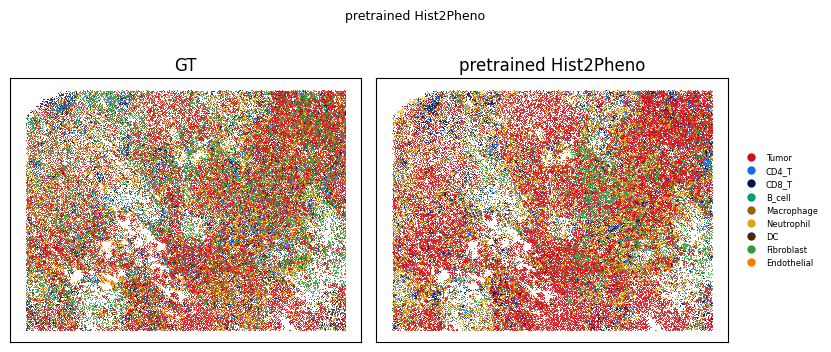

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__nwn-95916_aligned_737dafc9_composition_L2.png


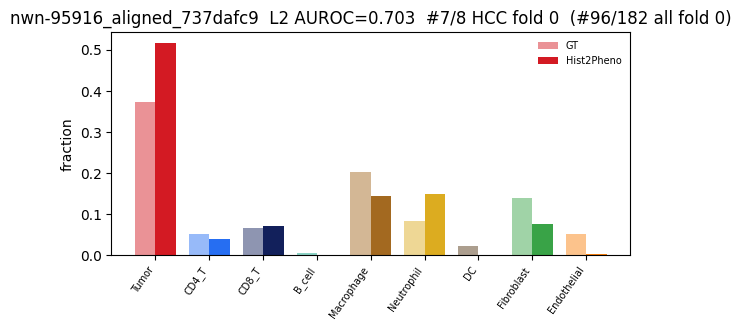

### uzr-70552_aligned_28fccc90  L2 AUROC=0.763  #5/8 HCC fold 0  (#51/182 all fold 0)

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__uzr-70552_aligned_28fccc90_spatial_L2_gt_pred.png


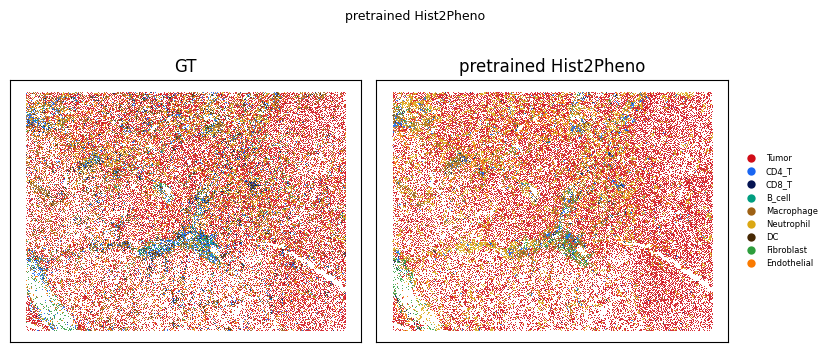

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__uzr-70552_aligned_28fccc90_composition_L2.png


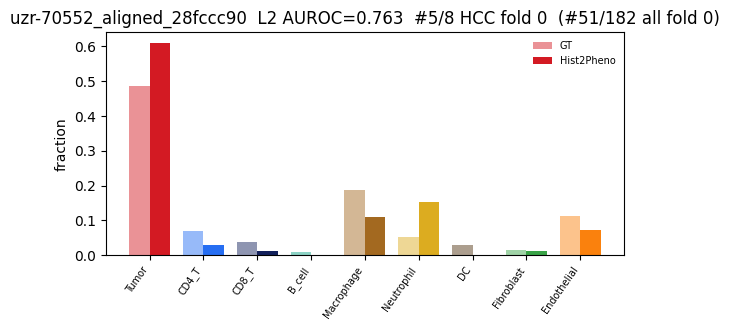

### lvr-76315_aligned_9c96ea90  L2 AUROC=0.791  #4/8 HCC fold 0  (#32/182 all fold 0)

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__lvr-76315_aligned_9c96ea90_spatial_L2_gt_pred.png


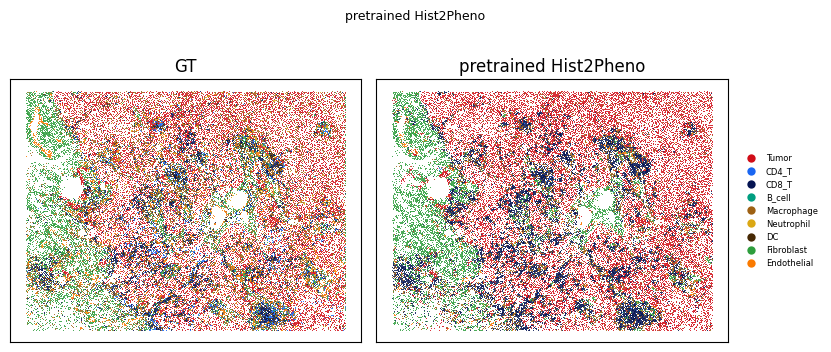

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__lvr-76315_aligned_9c96ea90_composition_L2.png


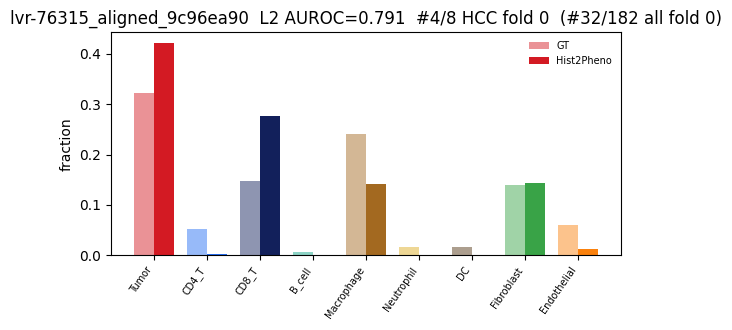

### tai-49708_aligned_459aad10  L2 AUROC=0.823  #2/8 HCC fold 0  (#16/182 all fold 0)

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__tai-49708_aligned_459aad10_spatial_L2_gt_pred.png


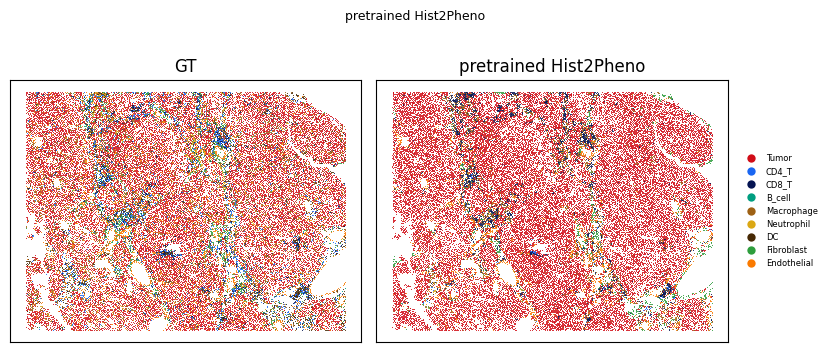

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC__tai-49708_aligned_459aad10_composition_L2.png


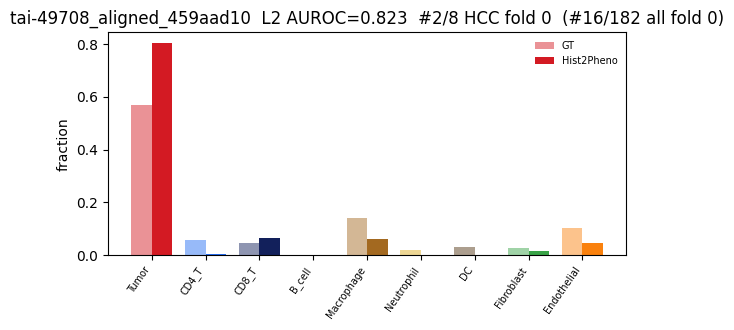

In [3]:
display(Markdown("## Current 4 slides — GT vs pretrained L2"))
for sample in viz:
    pred = iv.pred_paths(DATASET, sample)["pred"]
    if not pred.is_file():
        print("skip", sample, "(no matched_pred.h5ad)")
        continue
    display(Markdown(f"### {iv.rank_label(DATASET, sample)}"))
    fig = iv.plot_spatial_gt_pred(DATASET, sample, "L2", save=SAVE_FIGURES)
    display(fig)
    plt.close(fig)
    fig = iv.plot_composition(DATASET, sample, "L2", save=SAVE_FIGURES)
    display(fig)
    plt.close(fig)


## Paper set — top 5 HCC fold-0 by L2 AUROC

These are the five highest `macro_auc_L2_cells` among the 8 HCC fold-0 sections.
The rank table in the first code cell names them.

`SAVE_PAPER=True` writes 300 dpi PNGs under
`data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/`.


### Top 5 — 4×3 panels

### uzr-70552_aligned_aab73d87  L2 AUROC=0.838  #1/8 HCC fold 0  (#11/182 all fold 0)

missing panel uzr-70552_aligned_aab73d87


### tai-49708_aligned_459aad10  L2 AUROC=0.823  #2/8 HCC fold 0  (#16/182 all fold 0)

missing panel tai-49708_aligned_459aad10


### kqr-83230_aligned_3bba12d6  L2 AUROC=0.815  #3/8 HCC fold 0  (#23/182 all fold 0)

... (3 outputs left out)

### uzr-70552_aligned_28fccc90  L2 AUROC=0.763  #5/8 HCC fold 0  (#51/182 all fold 0)

missing panel uzr-70552_aligned_28fccc90


### Top 5 — GT vs pretrained L2

### uzr-70552_aligned_aab73d87  L2 AUROC=0.838  #1/8 HCC fold 0  (#11/182 all fold 0)

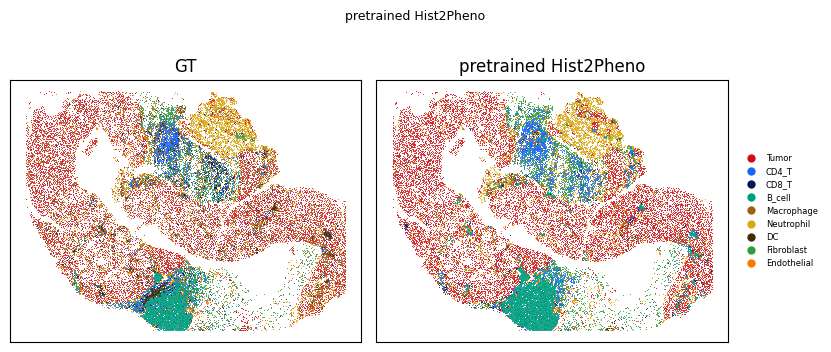

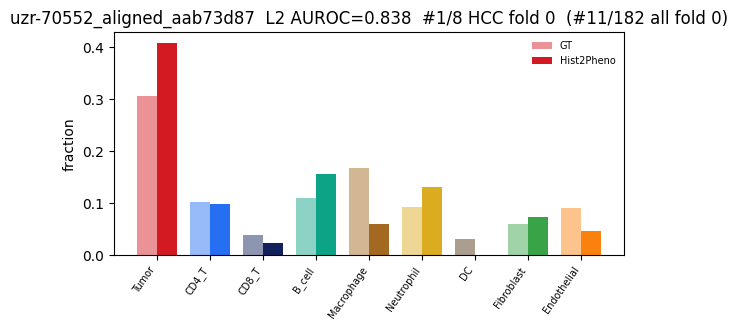

### tai-49708_aligned_459aad10  L2 AUROC=0.823  #2/8 HCC fold 0  (#16/182 all fold 0)

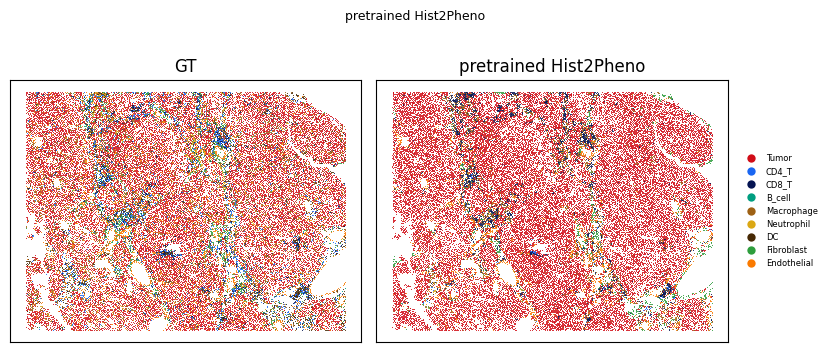

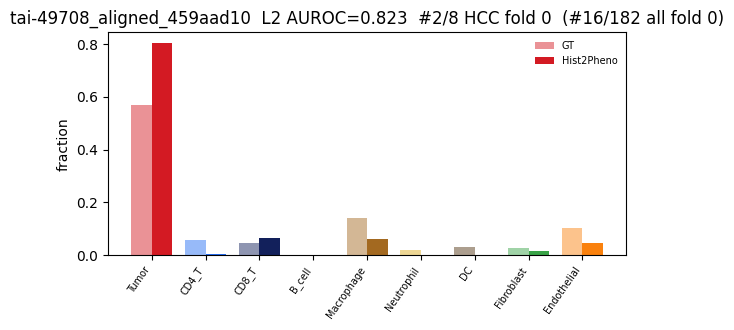

### kqr-83230_aligned_3bba12d6  L2 AUROC=0.815  #3/8 HCC fold 0  (#23/182 all fold 0)

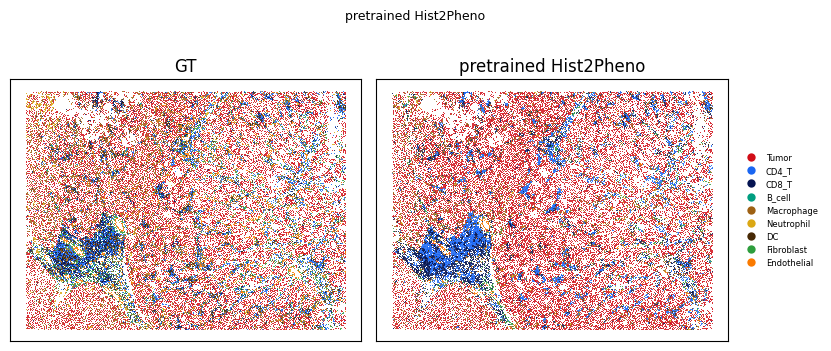

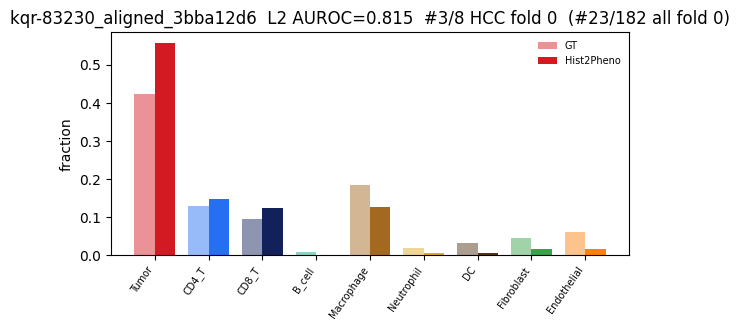

### lvr-76315_aligned_9c96ea90  L2 AUROC=0.791  #4/8 HCC fold 0  (#32/182 all fold 0)

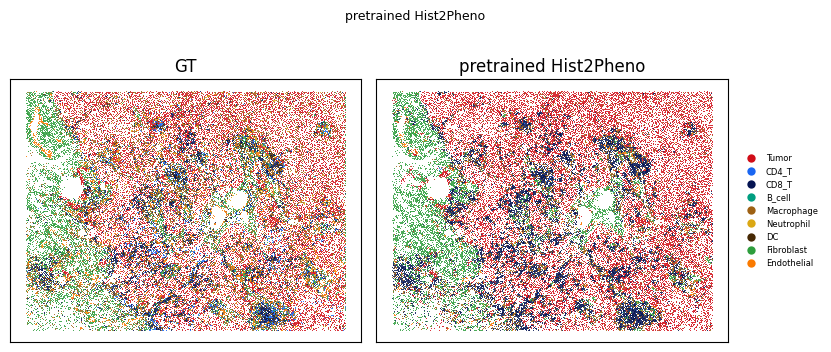

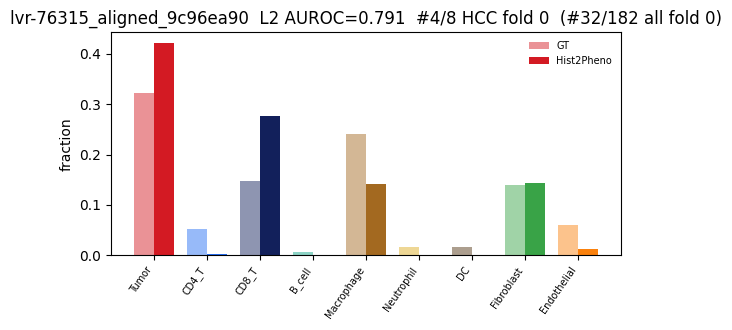

### uzr-70552_aligned_28fccc90  L2 AUROC=0.763  #5/8 HCC fold 0  (#51/182 all fold 0)

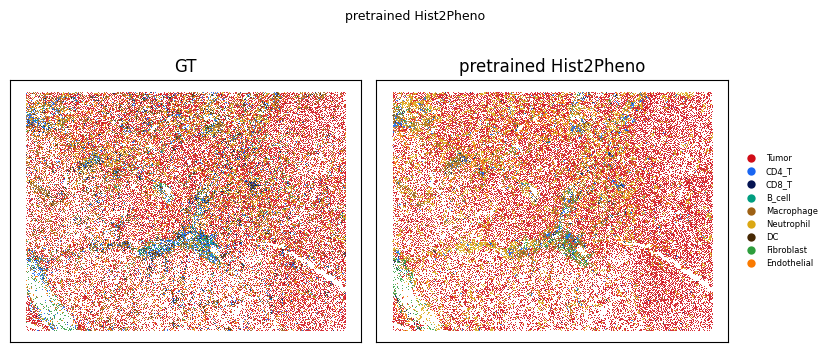

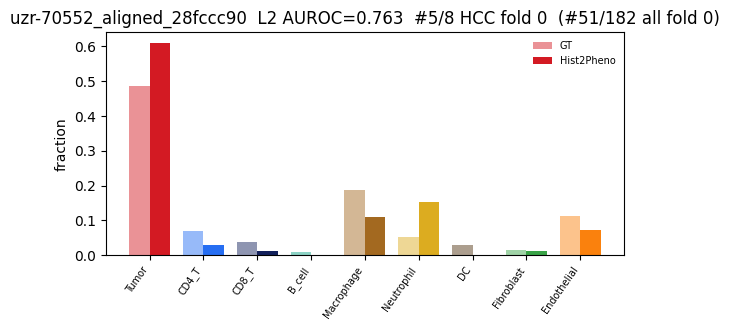

/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC_fold0_top5/01_uzr-70552_aligned_aab73d87_composition_L2.png
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC_fold0_top5/02_tai-49708_aligned_459aad10_composition_L2.png
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC_fold0_top5/03_kqr-83230_aligned_3bba12d6_composition_L2.png
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC_fold0_top5/04_lvr-76315_aligned_9c96ea90_composition_L2.png
/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC_fold0_top5/05_uzr-70552_a

Saved paper figures → `/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A2_adjacent_spatial_k8mean_paired_v2_seed42_deployment/internal_val_figures/HCC_fold0_top5`

In [4]:
display(Markdown("### Top 5 — 4×3 panels"))
for sample in top5:
    panel = iv.pred_paths(DATASET, sample)["panel"]
    display(Markdown(f"### {iv.rank_label(DATASET, sample)}"))
    if panel.is_file():
        display(Image(filename=str(panel)))
    else:
        print("missing panel", sample)

display(Markdown("### Top 5 — GT vs pretrained L2"))
for sample in top5:
    pred = iv.pred_paths(DATASET, sample)["pred"]
    if not pred.is_file():
        print("skip", sample)
        continue
    display(Markdown(f"### {iv.rank_label(DATASET, sample)}"))
    fig = iv.plot_spatial_gt_pred(DATASET, sample, "L2", save=False)
    display(fig)
    plt.close(fig)
    fig = iv.plot_composition(DATASET, sample, "L2", save=False)
    display(fig)
    plt.close(fig)

if SAVE_PAPER:
    out = iv.export_paper_sections(DATASET, top5)
    display(Markdown(f"Saved paper figures → `{out}`"))
